# Sales Demand Forecasting: daily orders on the Olist marketplace

**Task:** forecast the number of orders per day for the next **28 days** for a Brazilian
e-commerce marketplace (Olist, ~99k orders, 2016–2018).

**Why it matters:** a 4-week demand forecast drives warehouse staffing, courier capacity,
customer-support shifts and marketing budgets.

**Approach**
1. Build a clean daily series and choose a stable period (verified on a plot).
2. EDA: trend, weekly seasonality, Black Friday and two real 2018 disruptions.
3. Time-based split: the last 28 days are the test set; nothing from them is used for fitting.
4. Four models with the same 28-day horizon: **seasonal naive** baseline, **SARIMA**,
   **Prophet** with Brazilian holidays, **LightGBM** with calendar + lag features.
5. Compare on MAE, RMSE and MAPE; plot forecast vs actual.

In [1]:
import logging
import warnings
from itertools import product
from pathlib import Path

import holidays
import lightgbm as lgb
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from prophet import Prophet
from statsmodels.tsa.seasonal import STL
from statsmodels.tsa.statespace.sarimax import SARIMAX

warnings.filterwarnings("ignore")
logging.getLogger("cmdstanpy").disabled = True
logging.getLogger("prophet").setLevel(logging.WARNING)

SEED = 42
HORIZON = 28  # forecast horizon in days = size of the test set

# Figures go to ../reports/figures when run inside the repo, to ./figures elsewhere (e.g. Kaggle)
FIG_DIR = Path("../reports/figures") if Path("../reports").exists() else Path("figures")
FIG_DIR.mkdir(parents=True, exist_ok=True)

# Chart colours: actual = ink, baseline = grey, models = fixed categorical order
C = {"actual": "#0b0b0b", "naive": "#8a8986", "SARIMA": "#2a78d6",
     "Prophet": "#eb6834", "LightGBM": "#1baf7a", "muted": "#52514e"}
plt.rcParams.update({
    "figure.figsize": (11, 4), "figure.dpi": 110, "axes.spines.top": False,
    "axes.spines.right": False, "axes.grid": True, "grid.color": "#e6e5e1",
    "grid.linewidth": 0.6, "axes.edgecolor": "#8a8986", "axes.titleweight": "bold",
    "axes.titlesize": 12, "legend.frameon": False, "lines.linewidth": 1.6,
})

Importing plotly failed. Interactive plots will not work.


## 1. Load the data

One file is needed: `olist_orders_dataset.csv` (one row per order, with its status and purchase
timestamp). The cell looks for it on Kaggle (`olistbr/brazilian-ecommerce` attached as input),
then in `../data/`, and otherwise downloads it from Olist's public GitHub repository.

In [2]:
CANDIDATES = [
    Path("/kaggle/input/brazilian-ecommerce/olist_orders_dataset.csv"),
    Path("../data/olist_orders_dataset.csv"),
    Path("data/olist_orders_dataset.csv"),
]
SOURCE_URL = ("https://raw.githubusercontent.com/olist/work-at-olist-data/"
              "master/datasets/olist_orders_dataset.csv")

path = next((p for p in CANDIDATES if p.exists()), None)
orders = pd.read_csv(path or SOURCE_URL, parse_dates=["order_purchase_timestamp"])
print(f"Loaded from: {path or SOURCE_URL}")
print(f"{len(orders):,} orders, {orders.order_purchase_timestamp.min():%Y-%m-%d} → "
      f"{orders.order_purchase_timestamp.max():%Y-%m-%d}")
orders.order_status.value_counts()

Loaded from: ../data/olist_orders_dataset.csv
99,441 orders, 2016-09-04 → 2018-10-17


order_status
delivered      96478
shipped         1107
canceled         625
unavailable      609
invoiced         314
processing       301
created            5
approved           2
Name: count, dtype: int64

## 2. Build the daily series

* **Remove `canceled` and `unavailable` orders**: they are not real demand that has to be
  fulfilled. Every other status (delivered, shipped, invoiced, ...) is a placed order.
* Count orders per calendar day of `order_purchase_timestamp` (the moment the customer
  bought). `asfreq("D")` makes sure days without orders appear as 0 instead of disappearing.

Removed 1,234 canceled/unavailable orders


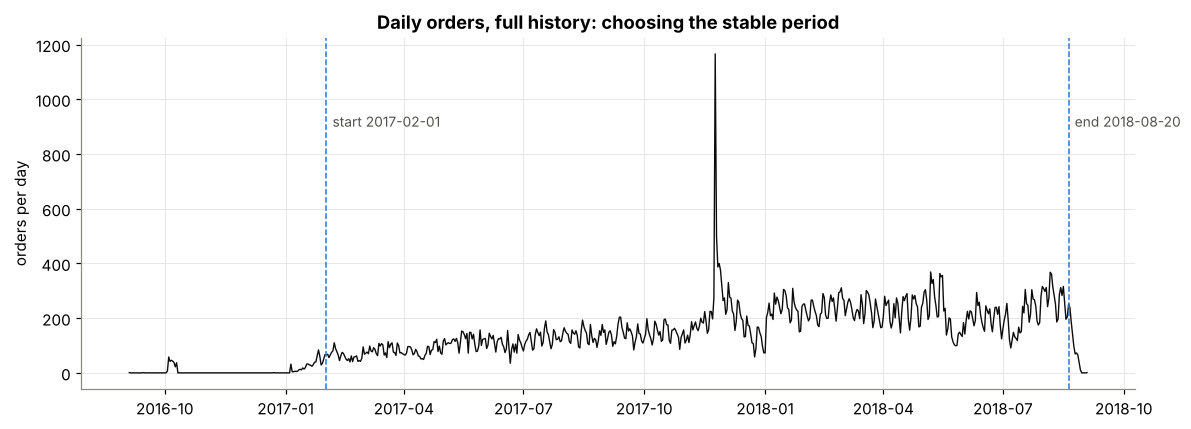

In [3]:
placed = orders[~orders.order_status.isin(["canceled", "unavailable"])]
daily_all = (placed.set_index("order_purchase_timestamp")
             .resample("D").size().asfreq("D", fill_value=0).rename("orders"))
print(f"Removed {len(orders) - len(placed):,} canceled/unavailable orders")

fig, ax = plt.subplots()
ax.plot(daily_all, color=C["actual"], lw=0.9)
for d, label in [("2017-02-01", "start 2017-02-01"), ("2018-08-20", "end 2018-08-20")]:
    ax.axvline(pd.Timestamp(d), color=C["SARIMA"], ls="--", lw=1)
    ax.annotate(label, (pd.Timestamp(d), 900), xytext=(4, 0), textcoords="offset points",
                color=C["muted"], fontsize=9)
ax.set(title="Daily orders, full history: choosing the stable period", ylabel="orders per day")
fig.tight_layout(); fig.savefig(FIG_DIR / "01_full_history.png", dpi=150); plt.show()

**Choosing the period (verified on the plot and in the numbers below):**
* **Start 2017-02-01.** 2016 has only a handful of days with orders, and January 2017 is
  still the platform's ramp-up (it starts at zero and averages ~25 orders a day, against
  60–100 a day from February on).
  Fitting on the ramp-up would teach the models a growth rate that no longer exists.
* **End 2018-08-20.** After that the count collapses (186 → 11 per day within a week, then
  zero). That is the dataset export being cut off, not a real fall in demand.

In [4]:
print("January 2017 (ramp-up):", daily_all["2017-01-01":"2017-01-31"].describe()[["mean", "min", "max"]].round(1).to_dict())
print("End of the export:")
print(daily_all["2018-08-17":"2018-09-03"].to_string())

January 2017 (ramp-up): {'mean': 25.4, 'min': 0.0, 'max': 84.0}
End of the export:
order_purchase_timestamp
2018-08-17    254
2018-08-18    196
2018-08-19    204
2018-08-20    252
2018-08-21    239
2018-08-22    186
2018-08-23    142
2018-08-24     97
2018-08-25     69
2018-08-26     73
2018-08-27     66
2018-08-28     39
2018-08-29     11
2018-08-30      0
2018-08-31      0
2018-09-01      0
2018-09-02      0
2018-09-03      1
Freq: D


In [5]:
y = daily_all["2017-02-01":"2018-08-20"].astype(float)
print(f"Series: {y.index.min():%Y-%m-%d} → {y.index.max():%Y-%m-%d}, {len(y)} days, "
      f"days with zero orders: {(y == 0).sum()}")

Series: 2017-02-01 → 2018-08-20, 566 days, days with zero orders: 0


## 3. Exploratory analysis

### 3.1 Trend, Black Friday and 2018 disruptions

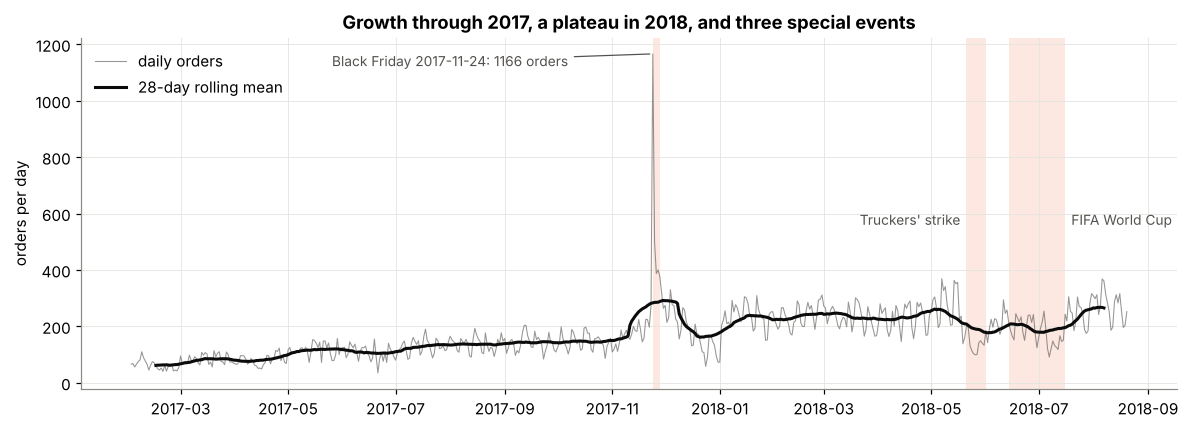

In [6]:
EVENTS = {  # dates are public knowledge, fixed before looking at the test period
    "Black Friday": ("2017-11-24", "2017-11-27"),
    "Truckers' strike": ("2018-05-21", "2018-05-31"),
    "FIFA World Cup": ("2018-06-14", "2018-07-15"),
}

fig, ax = plt.subplots()
ax.plot(y, color=C["muted"], lw=0.7, alpha=0.6, label="daily orders")
ax.plot(y.rolling(28, center=True).mean(), color=C["actual"], lw=2, label="28-day rolling mean")
for name, (a, b) in EVENTS.items():
    ax.axvspan(pd.Timestamp(a), pd.Timestamp(b) + pd.Timedelta(days=1), color=C["Prophet"], alpha=0.15, lw=0)
ax.annotate("Truckers' strike", (pd.Timestamp("2018-05-21"), 560), xytext=(-4, 0), textcoords="offset points",
            ha="right", fontsize=9, color=C["muted"])
ax.annotate("FIFA World Cup", (pd.Timestamp("2018-07-16"), 560), xytext=(4, 0), textcoords="offset points",
            fontsize=9, color=C["muted"])
ax.annotate(f"Black Friday 2017-11-24: {y['2017-11-24']:.0f} orders", (pd.Timestamp("2017-11-24"), y["2017-11-24"]),
            xytext=(-210, -8), textcoords="offset points", fontsize=9, color=C["muted"],
            arrowprops=dict(arrowstyle="-", color=C["muted"], lw=0.8))
ax.set(title="Growth through 2017, a plateau in 2018, and three special events", ylabel="orders per day")
ax.legend(loc="upper left")
fig.tight_layout(); fig.savefig(FIG_DIR / "02_trend_events.png", dpi=150); plt.show()

In [7]:
bf = y["2017-11-17":"2017-11-30"]
print(f"Black Friday 2017-11-24: {y['2017-11-24']:.0f} orders vs "
      f"{y['2017-11-10':'2017-11-23'].mean():.0f} on an average day of the two weeks before (×{y['2017-11-24'] / y['2017-11-10':'2017-11-23'].mean():.1f})")
weekly = y.resample("W-SUN").mean()
print("\nWeekly mean orders per day, spring-summer 2018:")
print(weekly["2018-05-06":"2018-08-19"].round(0).astype(int).to_string())

Black Friday 2017-11-24: 1166 orders vs 192 on an average day of the two weeks before (×6.1)

Weekly mean orders per day, spring-summer 2018:
order_purchase_timestamp
2018-05-06    252
2018-05-13    282
2018-05-20    261
2018-05-27    135
2018-06-03    154
2018-06-10    205
2018-06-17    216
2018-06-24    207
2018-07-01    199
2018-07-08    170
2018-07-15    141
2018-07-22    238
2018-07-29    233
2018-08-05    290
2018-08-12    280
2018-08-19    265
Freq: W-SUN


**What the plot shows**
* **Trend:** strong growth through 2017 (~100 → ~250 orders a day), then a plateau of
  ~230–270 in 2018.
* **Black Friday (24.11.2017):** 1,166 orders, about **6× a normal day**, with an elevated
  tail over the following weekend. A one-off outlier that a model has to treat as a special
  day, otherwise it inflates the trend and the variance.
* **Truckers' strike (21–31 May 2018):** a nationwide road-freight strike in Brazil;
  the weekly average fell to ~135 orders a day.
* **FIFA World Cup (14 June–15 July 2018):** demand dropped during the tournament, with a
  second dip after Brazil was knocked out on 6 July, and recovered immediately after the
  final.

The last two matter a lot for us: **they sit right before the test window**, and demand
recovers just as the test starts. A model that reads the World Cup dip as a new downward
trend will under-forecast. This is a realistic forecasting problem: recent history is not
always representative.

### 3.2 Weekly seasonality

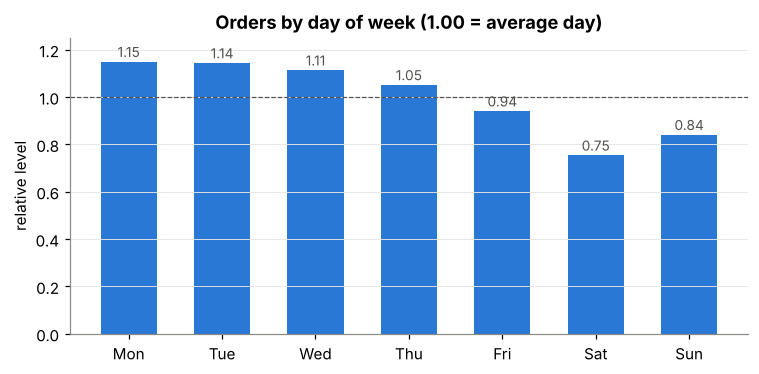

In [8]:
dow_names = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]
calm = y.drop(pd.concat([y[a:b] for a, b in EVENTS.values()]).index)  # exclude special events
dow_index = calm.groupby(calm.index.dayofweek).mean() / calm.mean()

fig, ax = plt.subplots(figsize=(7, 3.5))
bars = ax.bar(dow_names, dow_index.values, color=C["SARIMA"], width=0.6)
ax.axhline(1, color=C["muted"], lw=0.8, ls="--")
for b, v in zip(bars, dow_index.values):
    ax.annotate(f"{v:.2f}", (b.get_x() + b.get_width() / 2, v), xytext=(0, 3),
                textcoords="offset points", ha="center", fontsize=9, color=C["muted"])
ax.set(title="Orders by day of week (1.00 = average day)", ylabel="relative level", ylim=(0, 1.25))
ax.grid(axis="x", visible=False)
fig.tight_layout(); fig.savefig(FIG_DIR / "03_weekday.png", dpi=150); plt.show()

A clear **weekly cycle**: Monday and Tuesday are the busiest days, and Saturday is ~25%
below average. So the models need a **7-day seasonality**.

The STL decomposition below separates trend, weekly seasonality and the residual. The
weekly swing grows as the level grows (smaller in early 2017, larger later), so the
seasonality is roughly **multiplicative**: a percentage of the level, not a fixed number of
orders. That is why SARIMA is fitted on `log(orders)` and Prophet uses multiplicative
seasonality.

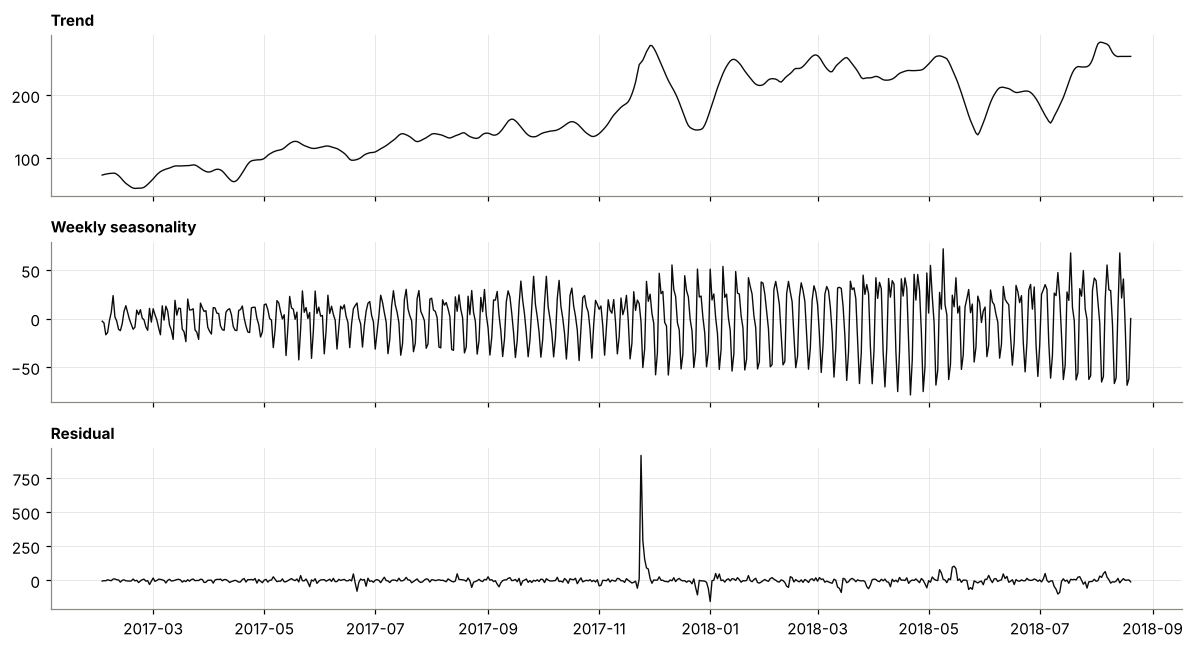

In [9]:
stl = STL(y, period=7, robust=True).fit()
fig, axes = plt.subplots(3, 1, figsize=(11, 6), sharex=True)
for ax, (comp, title) in zip(axes, [(stl.trend, "Trend"), (stl.seasonal, "Weekly seasonality"), (stl.resid, "Residual")]):
    ax.plot(comp, color=C["actual"], lw=0.9); ax.set_title(title, loc="left", fontsize=10)
fig.tight_layout(); fig.savefig(FIG_DIR / "04_stl.png", dpi=150); plt.show()

## 4. Train / test split by time

The **last 28 days (2018-07-24 → 2018-08-20) are the test set**, and everything before that is
training. **No random split:** in a time series neighbouring days are strongly correlated,
so a random split would put days *between* known neighbours into the test set. The model
would be interpolating, not forecasting, and the score would be over-optimistic. In
production we always forecast the future from the past, and the split must imitate that.

In [10]:
train, test = y.iloc[:-HORIZON], y.iloc[-HORIZON:]
print(f"Train: {train.index.min():%Y-%m-%d} → {train.index.max():%Y-%m-%d} ({len(train)} days)")
print(f"Test:  {test.index.min():%Y-%m-%d} → {test.index.max():%Y-%m-%d} ({len(test)} days), "
      f"mean {test.mean():.0f} orders/day, min {test.min():.0f}")

Train: 2017-02-01 → 2018-07-23 (538 days)
Test:  2018-07-24 → 2018-08-20 (28 days), mean 265 orders/day, min 175


## 5. Metrics

* **MAE**: average absolute error in orders. Easy to explain ("we miss by ~30 orders a day").
* **RMSE**: squares the errors first, so it penalises large misses more. Useful when one bad
  day is costly (e.g. not enough couriers).
* **MAPE**: average absolute error **in % of the actual value**. Scale-free, so it can be
  compared across products or stores. **Weakness:** it divides by the actual value, so when
  actuals are close to zero (a slow product, a night hour) it explodes or is undefined. It also
  penalises over-forecasts more than under-forecasts. Here it is safe: the smallest test value
  is 175 orders.

In [11]:
def metrics(actual, forecast) -> dict:
    a, f = np.asarray(actual, float), np.asarray(forecast, float)
    return {"MAE": np.mean(np.abs(a - f)),
            "RMSE": np.sqrt(np.mean((a - f) ** 2)),
            "MAPE, %": np.mean(np.abs((a - f) / a)) * 100}

forecasts = {}

## 6. Model 1: seasonal naive (baseline)

"Each day equals the same weekday one week earlier." Over a 28-day horizon we only know data
up to the end of the training set, so the **last observed week is repeated four times**.
Every real model has to beat this baseline, otherwise it adds complexity for nothing.

In [12]:
forecasts["Seasonal naive"] = pd.Series(np.tile(train.iloc[-7:].values, HORIZON // 7), index=test.index)
pd.DataFrame({"actual": test, "seasonal naive": forecasts["Seasonal naive"]}).head(10)

,actual,seasonal naive
order_purchase_timestamp,,
2018-07-24,270.0,219.0
2018-07-25,267.0,305.0
2018-07-26,245.0,253.0
2018-07-27,189.0,247.0
2018-07-28,175.0,185.0
2018-07-29,184.0,214.0
2018-07-30,280.0,304.0
2018-07-31,316.0,219.0
2018-08-01,308.0,305.0


## 7. Model 2: SARIMA with weekly seasonality

**SARIMA(p,d,q)(P,D,Q,7)** models the series as a function of its own past values
(AR, `p`) and past errors (MA, `q`), after differencing:
* `d=1` removes the trend (we model day-to-day changes),
* `D=1, s=7` removes the weekly pattern (we compare with the same weekday last week),
* `P, Q` are the seasonal AR/MA terms at lag 7.

We fit on **`log(orders)`**: weekly swings are proportional to the level (see STL), and the log
turns multiplicative effects into additive ones, which is what SARIMA assumes. The orders
`p, q, P, Q` are chosen by **AIC on the training data only** (small grid search).

In [13]:
log_train = np.log(train)
grid = []
for p, q, P, Q in product([0, 1, 2], [0, 1, 2], [0, 1], [0, 1]):
    try:
        fit = SARIMAX(log_train, order=(p, 1, q), seasonal_order=(P, 1, Q, 7)).fit(disp=False)
        grid.append(((p, 1, q), (P, 1, Q, 7), fit.aic))
    except Exception:
        continue
grid = pd.DataFrame(grid, columns=["order", "seasonal_order", "AIC"]).sort_values("AIC")
best_order, best_seasonal = grid.iloc[0, :2]
print(f"Best by AIC: SARIMA{best_order}x{best_seasonal}")
grid.head(5)

Best by AIC: SARIMA(1, 1, 1)x(0, 1, 1, 7)


,order,seasonal_order,AIC
17,"(1, 1, 1)","(0, 1, 1, 7)",-236.214928
19,"(1, 1, 1)","(1, 1, 1, 7)",-235.814488
9,"(0, 1, 2)","(0, 1, 1, 7)",-235.806958
11,"(0, 1, 2)","(1, 1, 1, 7)",-235.131447
29,"(2, 1, 1)","(0, 1, 1, 7)",-234.386871


In [14]:
sarima = SARIMAX(log_train, order=best_order, seasonal_order=best_seasonal).fit(disp=False)
sarima_fc = sarima.get_forecast(HORIZON)
# Back-transform: exp of the forecast median on the log scale
forecasts["SARIMA"] = np.exp(sarima_fc.predicted_mean).set_axis(test.index)
sarima_ci = np.exp(sarima_fc.conf_int(alpha=0.2)).set_axis(test.index)  # 80% interval for the plot

## 8. Model 3: Prophet with Brazilian holidays

Prophet (Meta) decomposes the series into **trend + weekly seasonality + holiday effects**
and fits them as a regression, so each component is interpretable.
* `add_country_holidays("BR")` adds the Brazilian public holidays (Carnival, Tiradentes,
  Independence Day, ...).
* The special events from the EDA (Black Friday + weekend, truckers' strike, World Cup) are
  added as custom "holidays". This tells Prophet that those dips and spikes are one-offs.
  Without them, the World Cup dip at the end of the training set pulls the trend down.
* `seasonality_mode="multiplicative"`: the weekly pattern scales with the level.
* Yearly seasonality is off: with ~1.5 years of data, one yearly cycle cannot be estimated
  reliably.

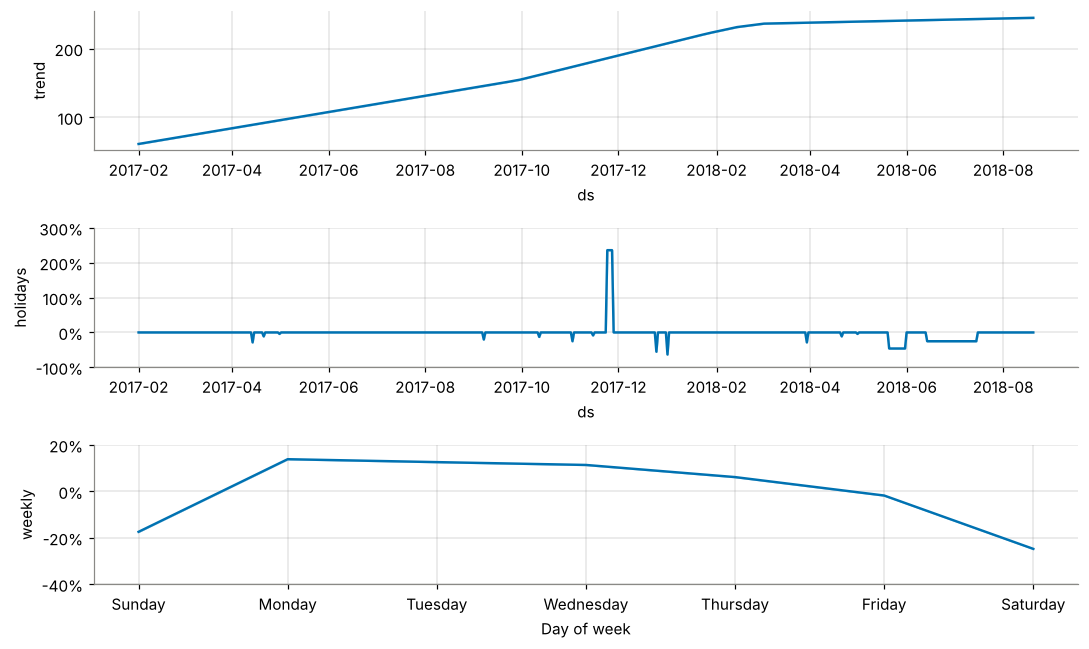

In [15]:
def prophet_events() -> pd.DataFrame:
    return pd.concat([pd.DataFrame({"holiday": name, "ds": pd.date_range(a, b)})
                      for name, (a, b) in EVENTS.items()], ignore_index=True)

def fit_prophet(train_series: pd.Series, with_events: bool = True) -> pd.Series:
    df = train_series.rename_axis("ds").reset_index(name="y")
    m = Prophet(weekly_seasonality=True, yearly_seasonality=False, daily_seasonality=False,
                seasonality_mode="multiplicative",
                holidays=prophet_events() if with_events else None)
    m.add_country_holidays(country_name="BR")
    m.fit(df)
    future = m.make_future_dataframe(periods=HORIZON)
    return m, m.predict(future)

prophet_model, prophet_pred = fit_prophet(train)
forecasts["Prophet"] = prophet_pred["yhat"].iloc[-HORIZON:].set_axis(test.index)
fig = prophet_model.plot_components(prophet_pred, figsize=(10, 6))
fig.savefig(FIG_DIR / "05_prophet_components.png", dpi=150); plt.show()

## 9. Model 4: LightGBM with calendar and lag features

Gradient boosting does not know about time. We turn forecasting into a **tabular regression**:
each row is a day, the target is the orders on that day, and the features describe the
calendar and the past.

**The leakage rule:** on the forecast date we know the data up to the end of training,
and we must predict up to **28 days ahead**. For the last test day, the most recent known
value is 28 days old. So **every lag must be ≥ 28 days**: `lag_28`, `lag_35`, `lag_42` (the
same weekday 4, 5 and 6 weeks ago). Rolling means are computed on the series **shifted by 28
days**. With `lag_1` or `lag_7` the model would train fine but in the test it would need
values from inside the test period, which do not exist at forecast time. That is data leakage,
and it makes the offline score better than anything achievable in production.

This lets LightGBM forecast all 28 days at once from known data (the "direct" strategy), with
no recursion.

| Feature | Meaning |
|---|---|
| `dayofweek`, `month`, `day` | calendar position (weekly cycle, month-end effects) |
| `is_holiday` | Brazilian public holiday (`holidays` package) |
| `lag_28`, `lag_35`, `lag_42` | orders on the same weekday 4, 5 and 6 weeks earlier |
| `rolling_mean_7`, `rolling_mean_28` | average level of the week / 4 weeks ending 28 days earlier |
| `is_event` | the day is inside a special event (Black Friday, strike, World Cup) |
| `lag_28_is_event` | the day used by `lag_28` was inside an event, so the lag is not representative |

Newest date used by lag_28 in the test set: 2018-07-23 | last training day: 2018-07-23


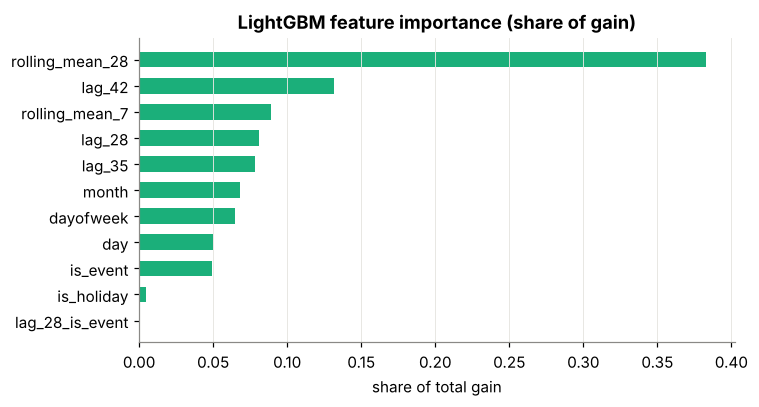

In [16]:
br_holidays = holidays.Brazil(years=range(2016, 2019))
event_flag = pd.Series(0, index=y.index)
for a, b in EVENTS.values():
    event_flag[a:b] = 1

feat = pd.DataFrame({"orders": y})
feat["dayofweek"] = feat.index.dayofweek
feat["month"] = feat.index.month
feat["day"] = feat.index.day
feat["is_holiday"] = feat.index.isin(pd.to_datetime(list(br_holidays.keys()))).astype(int)
for lag in (28, 35, 42):
    feat[f"lag_{lag}"] = feat["orders"].shift(lag)
for w in (7, 28):
    feat[f"rolling_mean_{w}"] = feat["orders"].shift(HORIZON).rolling(w).mean()
feat["is_event"] = event_flag
feat["lag_28_is_event"] = event_flag.shift(28)

BASE_FEATURES = ["dayofweek", "month", "day", "is_holiday", "lag_28", "lag_35", "lag_42",
                 "rolling_mean_7", "rolling_mean_28"]
FEATURES = BASE_FEATURES + ["is_event", "lag_28_is_event"]

feat_train = feat.loc[train.index].dropna()   # first 42+ days have no lags yet
feat_test = feat.loc[test.index]
assert feat_test[FEATURES].notna().all().all()
# Leakage check: the newest value any test feature depends on is from the training period
print("Newest date used by lag_28 in the test set:", (test.index.max() - pd.Timedelta(days=28)).date(),
      "| last training day:", train.index.max().date())

def fit_lgbm(features):
    model = lgb.LGBMRegressor(n_estimators=300, learning_rate=0.03, num_leaves=15,
                              min_child_samples=10, subsample=0.8, subsample_freq=1,
                              colsample_bytree=0.8, random_state=SEED, verbose=-1)
    model.fit(feat_train[features], feat_train["orders"])
    return model, pd.Series(model.predict(feat_test[features]), index=test.index)

lgbm, forecasts["LightGBM"] = fit_lgbm(FEATURES)

imp = pd.Series(lgbm.booster_.feature_importance("gain"), index=FEATURES).sort_values()
fig, ax = plt.subplots(figsize=(7, 3.8))
ax.barh(imp.index, imp / imp.sum(), color=C["LightGBM"], height=0.6)
ax.set(title="LightGBM feature importance (share of gain)", xlabel="share of total gain")
ax.grid(axis="y", visible=False)
fig.tight_layout(); fig.savefig(FIG_DIR / "06_lgbm_importance.png", dpi=150); plt.show()

## 10. Results
### 10.1 Comparison table (test period, 28 days)

In [17]:
results = (pd.DataFrame({name: metrics(test, fc) for name, fc in forecasts.items()}).T
           .sort_values("MAPE, %").round(2))
naive_mape = results.loc["Seasonal naive", "MAPE, %"]
results["MAPE vs naive"] = (results["MAPE, %"] - naive_mape).round(2).map(lambda v: f"{v:+.2f} pp")
results.index.name = "Model"
results.to_csv(FIG_DIR.parent / "results.csv")
results

,MAE,RMSE,"MAPE, %",MAPE vs naive
Model,,,,
Prophet,30.24,40.21,10.70,-3.21 pp
SARIMA,28.44,34.86,10.77,-3.14 pp
Seasonal naive,38.89,51.23,13.91,+0.00 pp
LightGBM,42.55,49.72,15.80,+1.89 pp


### 10.2 Forecast vs actual

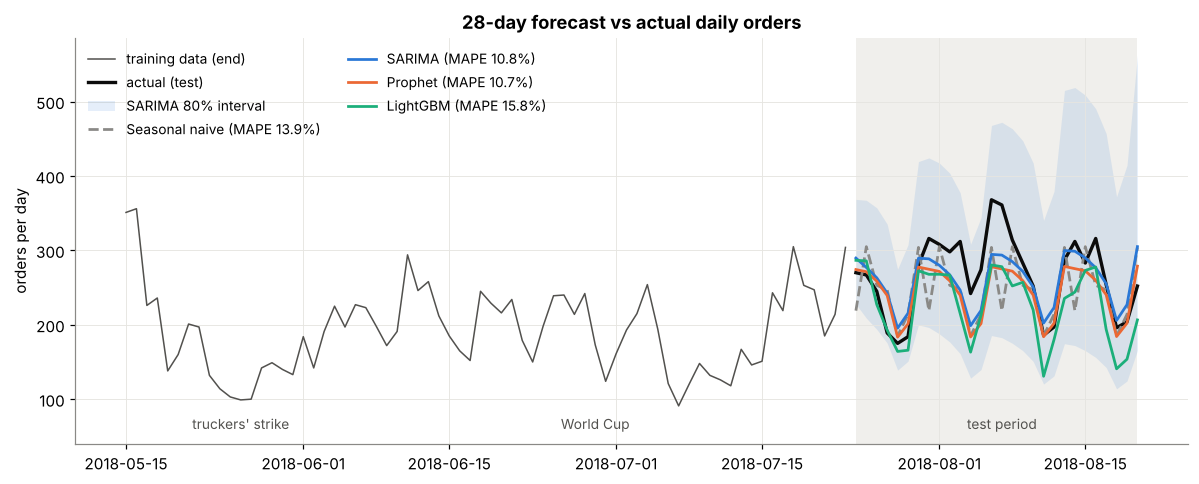

In [18]:
fig, ax = plt.subplots(figsize=(11, 4.5))
hist = y["2018-05-15":train.index.max()]
ax.plot(hist, color=C["muted"], lw=1, label="training data (end)")
ax.axvspan(test.index.min(), test.index.max(), color="#f0efec", lw=0, zorder=0)
ax.plot(test, color=C["actual"], lw=2.2, label="actual (test)")
ax.fill_between(test.index, sarima_ci.iloc[:, 0], sarima_ci.iloc[:, 1], color=C["SARIMA"], alpha=0.12, lw=0,
                label="SARIMA 80% interval")
styles = {"Seasonal naive": dict(color=C["naive"], ls="--"), "SARIMA": dict(color=C["SARIMA"]),
          "Prophet": dict(color=C["Prophet"]), "LightGBM": dict(color=C["LightGBM"])}
for name, fc in forecasts.items():
    ax.plot(fc, lw=1.8, label=f"{name} (MAPE {results.loc[name, 'MAPE, %']:.1f}%)", **styles[name])
ax.annotate("truckers' strike", (pd.Timestamp("2018-05-26"), 60), fontsize=9, color=C["muted"], ha="center")
ax.annotate("World Cup", (pd.Timestamp("2018-06-29"), 60), fontsize=9, color=C["muted"], ha="center")
ax.annotate("test period", (pd.Timestamp("2018-08-07"), 60), fontsize=9, color=C["muted"], ha="center")
ax.set_ylim(40, None)
ax.set(title="28-day forecast vs actual daily orders", ylabel="orders per day")
ax.legend(loc="upper left", ncol=2, fontsize=9)
fig.tight_layout(); fig.savefig(FIG_DIR / "07_forecast_vs_actual.png", dpi=150); plt.show()

### 10.3 What made the difference: handling the special events

Same models, same split, but **without** the event information. This shows how much of the
improvement comes from domain knowledge rather than from the algorithm.

In [19]:
_, prophet_plain = fit_prophet(train, with_events=False)
_, lgbm_plain = fit_lgbm(BASE_FEATURES)
ablation = pd.DataFrame({
    "Prophet, BR holidays only": metrics(test, prophet_plain["yhat"].iloc[-HORIZON:].values),
    "Prophet, BR holidays + events": metrics(test, forecasts["Prophet"]),
    "LightGBM, required features only": metrics(test, lgbm_plain),
    "LightGBM, + event features": metrics(test, forecasts["LightGBM"]),
}).T.round(2)
ablation

,MAE,RMSE,"MAPE, %"
"Prophet, BR holidays only",74.09,82.77,26.53
"Prophet, BR holidays + events",30.24,40.21,10.70
"LightGBM, required features only",56.05,62.98,21.12
"LightGBM, + event features",42.55,49.72,15.80


## 11. Conclusions

* **SARIMA (on log orders) and Prophet are tied at the top**: MAPE 10.8% and 10.7%, against
  13.9% for the seasonal naive baseline, about 3 percentage points better. SARIMA has the lowest
  MAE (−27% vs naive) and RMSE, so it makes fewer large misses, and I would pick it as the main
  model. Prophet's components (trend, weekday, holidays) are easier to explain to the business.
  A 0.07 pp MAPE gap on 28 days is noise, not a real difference.
* **Seasonal naive is a strong baseline.** The weekly cycle explains most of the variation, so
  a model has to earn its complexity.
* **LightGBM is the weakest here.** That is not because boosting is bad. With a 28-day horizon
  it may only use lags ≥ 28, and those lags fall straight into the World Cup dip. Its
  features say "demand is low" exactly when demand recovered. Boosting shines with many
  related series (e.g. per-category or per-state forecasts) and richer features (promotions,
  prices, marketing).
* **Domain knowledge matters more than the algorithm.** Telling Prophet and LightGBM about the
  Black Friday / strike / World Cup windows cut their MAPE by roughly 16 and 5 points
  (section 10.3). The event dates come from the calendar, not from the test data.

**Limitations and next steps**
* A single 28-day test window is a small sample. A rolling-origin backtest (several
  consecutive 28-day windows) would give a more reliable ranking.
* The model variants were motivated by the EDA, and section 10.3 shows their effect on the same
  test window. A stricter setup would choose them on a separate validation window.
* Forecast intervals (SARIMA and Prophet provide them) matter more for planning than the point
  forecast: staffing should cover the upper bound.
* Next: forecast per product category or state and reconcile the totals, and add
  promotions and marketing spend as regressors.

## Interview notes

* **Why not a random split?** Neighbouring days are correlated, and a random split leaks the
  future into training, so the model interpolates instead of forecasting. The score becomes too
  optimistic.
* **Why lags ≥ 28 in LightGBM?** The horizon is 28 days. For the last forecast day the newest
  known value is 28 days old. A shorter lag would use values that do not exist at forecast time
  (data leakage).
* **When is MAPE a bad metric?** When actual values are near zero (division by a tiny number),
  for intermittent demand, and when over- and under-forecasting should be penalised equally.
  Alternatives are MAE, WAPE (sum of absolute errors / sum of actuals) and MASE (error relative
  to the naive forecast).
* **Why log for SARIMA?** The weekly swing is proportional to the level (multiplicative). The
  log makes it additive and stabilises the variance.